# Diabetes Prediction Using Machine Learning Classification Algorithms

**Reference paper:** Shamriz Nahzat and Mete Yağanoğlu (2021).

## Important distinction
This notebook contains two separate things:
1. **My experiment:** scores calculated by running the code on the supplied CSV. The chart titled *Accuracy of Models on This Test Set* is generated from those real outputs.
2. **Published paper results:** a reference table transcribed from the paper. The chart titled *Accuracy reported in the research paper* displays those published numbers; it is not an output from the local model run.

The paper reports Random Forest accuracy of 88.31% for the experiment with two engineered features. The paper does not specify every detail needed to reproduce its exact data split, preprocessing, random seeds, and model settings. So it is not scientifically valid to force the local scores to match by replacing measured results with the paper's numbers. This notebook keeps both results clearly labelled for a fair comparison.


## 1. Import libraries

In [25]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)

RANDOM_STATE = 42
%matplotlib inline

# ---------- Unified visual theme ----------
PRIMARY = "#63488A"
SECONDARY = "#293DA1"
ACCENT = "#8CAED8"
LIGHT_1 = "#CFCFEE"
LIGHT_2 = "#7C59B0"
LIGHT_3 = "#88B1E0"
PLOT_BG = "#F7F8FC"
TEXT_COLOR = "#1B203E"
MUTED_COLOR = "#040B1C"
GRID_COLOR = "#D5E1FB"
GOLD_ACCENT = "#5D95DA"

sns.set_theme(style="whitegrid", font_scale=0.95, rc={
    "axes.facecolor": "white",
    "figure.facecolor": PLOT_BG,
    "axes.edgecolor": GRID_COLOR,
    "axes.labelcolor": TEXT_COLOR,
    "xtick.color": TEXT_COLOR,
    "ytick.color": TEXT_COLOR,
    "text.color": TEXT_COLOR,
    "grid.color": GRID_COLOR,
    "axes.titleweight": "bold",
})

def style_table(data, title, precision=2, hide_index=False):
    """One consistent style for every displayed DataFrame in this notebook."""
    styler = data.style.format(precision=precision).set_caption(title)
    if hide_index:
        styler = styler.hide(axis="index")
    return (
        styler
        .set_properties(**{
            "text-align": "center",
            "color": TEXT_COLOR,
            "padding": "8px 10px",
            "border": f"1px solid {GRID_COLOR}",
            "font-size": "10.5pt",
        })
        .set_table_styles([
            {"selector": "caption", "props": [
                ("caption-side", "top"), ("font-size", "14px"),
                ("font-weight", "700"), ("color", PRIMARY),
                ("text-align", "left"), ("padding", "10px 4px")
            ]},
            {"selector": "th", "props": [
                ("background-color", PRIMARY), ("color", "#FFFFFF"),
                ("text-align", "center"), ("font-weight", "700"),
                ("padding", "9px 10px"), ("border", f"1px solid {PRIMARY}")
            ]},
            {"selector": "tbody tr:nth-child(odd)", "props": [
                ("background-color", "#FFFFFF")
            ]},
            {"selector": "tbody tr:nth-child(even)", "props": [
                ("background-color", LIGHT_1)
            ]},
            {"selector": "tbody tr:hover", "props": [
                ("background-color", LIGHT_3)
            ]},
            {"selector": "table", "props": [
                ("border-collapse", "collapse"), ("border-radius", "8px"),
                ("overflow", "hidden")
            ]}
        ])
    )

def style_schema(data):
    """Styled replacement for the plain-text df.info() output."""
    schema = pd.DataFrame({
        "Column": data.columns,
        "Non-Null Count": data.notna().sum().values,
        "Data Type": data.dtypes.astype(str).values,
        "Missing Values": data.isna().sum().values
    })
    return style_table(schema, "Dataset Schema & Data Quality", precision=0, hide_index=True)


## 2. Load the dataset


In [26]:
from pathlib import Path


DATA_PATH = r"C:\Users\NoteBook\Desktop\Diabetes-Project\dataset\diabetes (1).csv"
if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find diabetes.csv. Put the CSV beside this notebook or update possible_paths."
    )

df = pd.read_csv(DATA_PATH)


print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

display(style_table(df.head(), "Dataset Preview — First 5 Records", precision=2, hide_index=True))
display(style_schema(df))

outcome_summary = pd.DataFrame({
    "Count": df["Outcome"].value_counts().sort_index(),
    "Percentage (%)": (df["Outcome"].value_counts(normalize=True).sort_index() * 100).round(2)
})
outcome_summary.index = ["0 — No diabetes", "1 — Diabetes"]
display(style_table(outcome_summary, "Target Distribution (Outcome)", precision=2))

Dataset shape: 768 rows × 9 columns


Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
6,148,72,35,0,33.60,0.63,50,1
1,85,66,29,0,26.60,0.35,31,0
8,183,64,0,0,23.30,0.67,32,1
1,89,66,23,94,28.10,0.17,21,0
0,137,40,35,168,43.10,2.29,33,1


Column,Non-Null Count,Data Type,Missing Values
Pregnancies,768,int64,0
Glucose,768,int64,0
BloodPressure,768,int64,0
SkinThickness,768,int64,0
Insulin,768,int64,0
BMI,768,float64,0
DiabetesPedigreeFunction,768,float64,0
Age,768,int64,0
Outcome,768,int64,0


,Count,Percentage (%)
0 — No diabetes,500,65.10
1 — Diabetes,268,34.90


## 3. Exploratory data analysis

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


,Zero count
Pregnancies,111
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,500


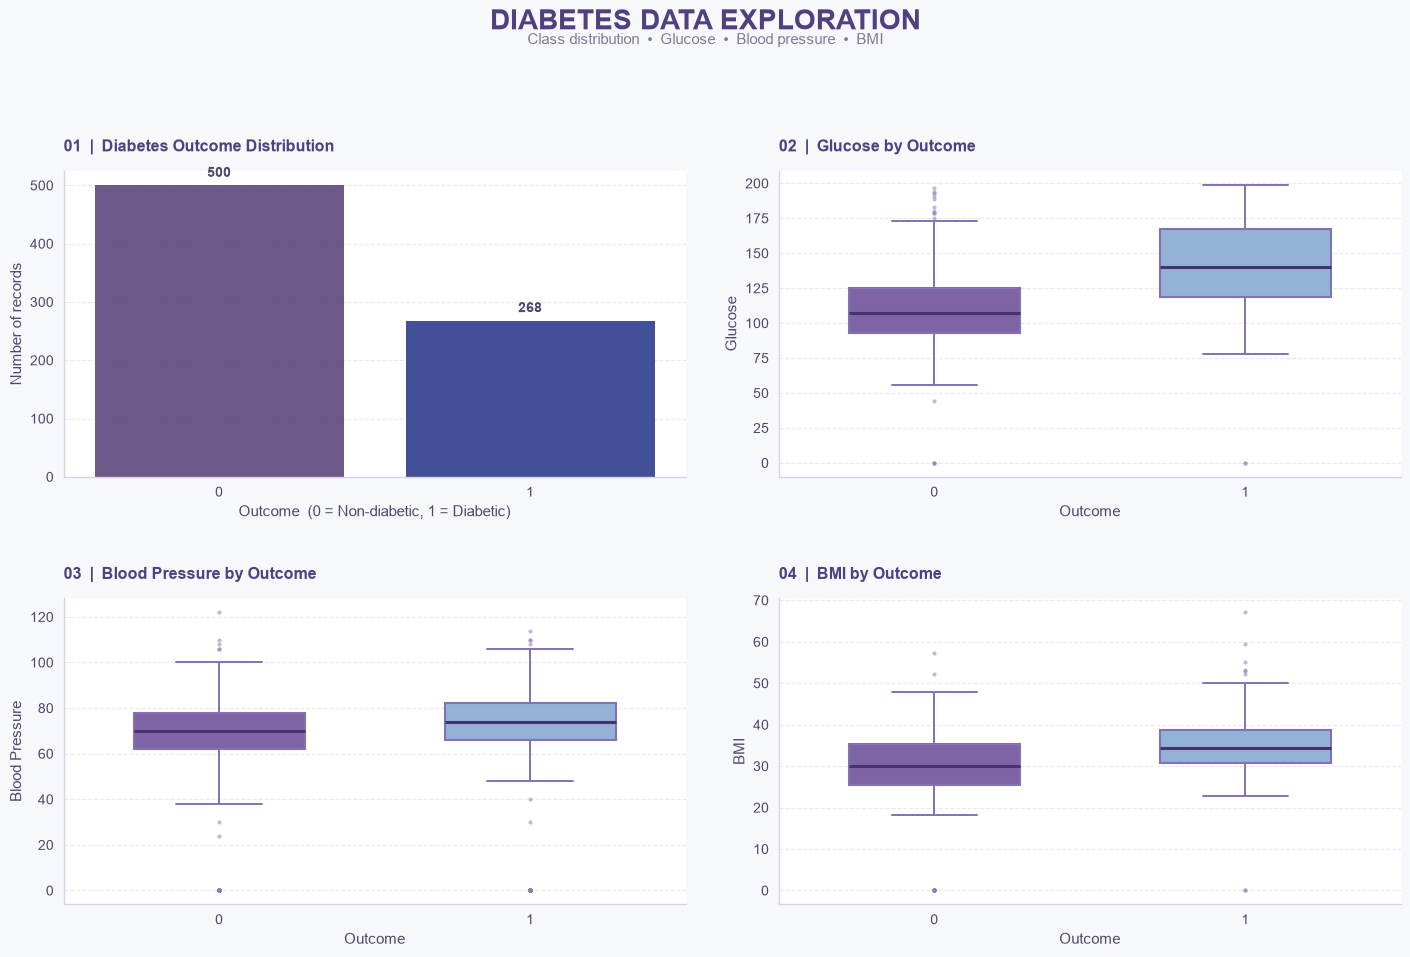

In [27]:
# ---------- EDA: Elegant Purple & Blue Theme ----------
purple = PRIMARY
blue = SECONDARY
light_purple = LIGHT_2
light_blue = LIGHT_3
background = PLOT_BG
text_color = TEXT_COLOR

# ---------- Summary Tables ----------
display(
    df.describe().round(2).style
    .set_caption("Dataset — Descriptive Statistics")
    .background_gradient(cmap="Purples", axis=None)
    .format("{:.2f}")
    .set_table_styles([
        {"selector": "caption", "props": [
            ("caption-side", "top"),
            ("background-color", "#514080"),
            ("color", "white"),
            ("font-size", "14px"),
            ("font-weight", "bold"),
            ("padding", "10px"),
            ("border-radius", "6px")
        ]},
        {"selector": "th", "props": [
            ("background-color", "#EAE5F5"),
            ("color", "#514080"),
            ("font-weight", "bold"),
            ("padding", "8px"),
            ("border", "1px solid #DDD5EC")
        ]},
        {"selector": "td", "props": [
            ("padding", "7px"),
            ("border", "1px solid #EEEAF5")
        ]}
    ])
)

zero_counts = (df == 0).sum().to_frame("Zero count")

display(
    zero_counts.style
    .set_caption("Zero Values by Column")
    .background_gradient(cmap="PuBu", axis=None)
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("background-color", "#514080"),
                ("color", "white"),
                ("font-size", "14px"),
                ("font-weight", "bold"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("background-color", "#EAE5F5"),
                ("color", "#514080"),
                ("font-weight", "bold"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "6px"),
                ("border", "1px solid #EEEAF5")
            ]
        }
    ])
)

# ---------- Four-Panel Dashboard ----------
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.patch.set_facecolor(background)

fig.suptitle(
    "DIABETES DATA EXPLORATION",
    fontsize=20,
    fontweight="bold",
    color="#514080",
    y=0.98
)

fig.text(
    0.5, 0.945,
    "Class distribution  •  Glucose  •  Blood pressure  •  BMI",
    ha="center",
    fontsize=11,
    color="#827895"
)

# ---------- Shared Chart Styling ----------
for ax in axes.flat:
    ax.set_facecolor("#FFFFFF")

    ax.grid(
        axis="y",
        color="#E8E2F1",
        linewidth=0.8,
        linestyle="--",
        alpha=0.85
    )
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color("#D9D1E8")
    ax.spines["bottom"].set_color("#D9D1E8")
    ax.spines["left"].set_linewidth(1.0)
    ax.spines["bottom"].set_linewidth(1.0)

    ax.tick_params(
        axis="both",
        colors="#514568",
        labelsize=10,
        length=0,
        pad=7
    )

    ax.xaxis.label.set_color("#514568")
    ax.yaxis.label.set_color("#514568")
    ax.xaxis.label.set_size(11)
    ax.yaxis.label.set_size(11)

    ax.title.set_fontsize(12)
    ax.title.set_fontweight("bold")
    ax.title.set_color("#514080")

# ---------- 1. Outcome Distribution ----------
sns.countplot(
    data=df,
    x="Outcome",
    hue="Outcome",
    palette={0: purple, 1: blue},
    legend=False,
    ax=axes[0, 0]
)

axes[0, 0].set_title(
    "01  |  Diabetes Outcome Distribution",
    loc="left",
    fontweight="bold",
    color="#514080",
    pad=14
)
axes[0, 0].set_xlabel("Outcome  (0 = Non-diabetic, 1 = Diabetic)")
axes[0, 0].set_ylabel("Number of records")

for container in axes[0, 0].containers:
    axes[0, 0].bar_label(
        container,
        fmt="%d",
        padding=4,
        color="#514568",
        fontsize=10,
        fontweight="bold"
    )

# Rounded bar corners, preserving values and dimensions
for patch in axes[0, 0].patches:
    patch.set_linewidth(0)
    patch.set_alpha(0.95)
    # ---------- 2. Glucose ----------
sns.boxplot(
    data=df,
    x="Outcome",
    y="Glucose",
    hue="Outcome",
    palette={0: light_purple, 1: light_blue},
    legend=False,
    width=0.55,
    linewidth=1.5,
    ax=axes[0, 1],
    boxprops={"edgecolor": "#8272B3"},
    medianprops={"color": "#44336F", "linewidth": 2.2},
    whiskerprops={"color": "#8272B3", "linewidth": 1.4},
    capprops={"color": "#8272B3", "linewidth": 1.4},
    flierprops={
        "marker": "o",
        "markersize": 3,
        "markerfacecolor": "#8D80B8",
        "markeredgecolor": "none",
        "alpha": 0.55
    }
)

axes[0, 1].set_title(
    "02  |  Glucose by Outcome",
    loc="left",
    fontweight="bold",
    color="#514080",
    pad=14
)
axes[0, 1].set_xlabel("Outcome")
axes[0, 1].set_ylabel("Glucose")

# ---------- 3. Blood Pressure ----------
sns.boxplot(
    data=df,
    x="Outcome",
    y="BloodPressure",
    hue="Outcome",
    palette={0: light_purple, 1: light_blue},
    legend=False,
    width=0.55,
    linewidth=1.5,
    ax=axes[1, 0],
    boxprops={"edgecolor": "#8272B3"},
    medianprops={"color": "#44336F", "linewidth": 2.2},
    whiskerprops={"color": "#8272B3", "linewidth": 1.4},
    capprops={"color": "#8272B3", "linewidth": 1.4},
    flierprops={
        "marker": "o",
        "markersize": 3,
        "markerfacecolor": "#8D80B8",
        "markeredgecolor": "none",
        "alpha": 0.55
    }
)

axes[1, 0].set_title(
    "03  |  Blood Pressure by Outcome",
    loc="left",
    fontweight="bold",
    color="#514080",
    pad=14
)
axes[1, 0].set_xlabel("Outcome")
axes[1, 0].set_ylabel("Blood Pressure")

# ---------- 4. BMI ----------
sns.boxplot(
    data=df,
    x="Outcome",
    y="BMI",
    hue="Outcome",
    palette={0: light_purple, 1: light_blue},
    legend=False,
    width=0.55,
    linewidth=1.5,
    ax=axes[1, 1],
    boxprops={"edgecolor": "#8272B3"},
    medianprops={"color": "#44336F", "linewidth": 2.2},
    whiskerprops={"color": "#8272B3", "linewidth": 1.4},
    capprops={"color": "#8272B3", "linewidth": 1.4},
    flierprops={
        "marker": "o",
        "markersize": 3,
        "markerfacecolor": "#8D80B8",
        "markeredgecolor": "none",
        "alpha": 0.55
    }
)

axes[1, 1].set_title(
    "04  |  BMI by Outcome",
    loc="left",
    fontweight="bold",
    color="#514080",
    pad=14
)
axes[1, 1].set_xlabel("Outcome")
axes[1, 1].set_ylabel("BMI")

# ---------- Final Layout: Original Size ----------
plt.tight_layout(
    rect=[0.025, 0.025, 0.975, 0.91],
    h_pad=3,
    w_pad=2.5
)

plt.show()

## 4. Preprocessing and train/test split

The dataset contains zero values that are usually treated as invalid measurements in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI`. Zeros in `Pregnancies` and `Outcome` remain unchanged.

To prevent data leakage, split first, then fit the imputer using training data only. This is a defensible implementation choice; the paper does not specify enough detail to guarantee that it matches the authors' exact procedure.

In [28]:
df_clean = df.copy()
invalid_zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df_clean[invalid_zero_cols] = df_clean[invalid_zero_cols].replace(0, np.nan)

X = df_clean.drop(columns="Outcome")
y = df_clean["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_imp = pd.DataFrame(
    imputer.transform(X_test), columns=X_test.columns, index=X_test.index
)

print("Train:", X_train_imp.shape, " Test:", X_test_imp.shape)
print("Missing values after imputation:", X_train_imp.isna().sum().sum(),
        X_test_imp.isna().sum().sum())

Train: (537, 8)  Test: (231, 8)
Missing values after imputation: 0 0


## 5. Feature sets and models

The paper's two added features are `BloodPressure > 80` and `(BloodPressure > 80) & (Glucose > 105)`. Imputation is fitted on training data only to avoid test-data leakage.


In [29]:
# ---------- Feature Engineering ----------
def add_paper_features(X):
    X = X.copy()

    X["BP_GT80"] = (X["BloodPressure"] > 80).astype(int)

    X["BP80_Glucose105"] = (
        (X["BloodPressure"] > 80) &
        (X["Glucose"] > 105)
    ).astype(int)

    return X


X_train_fe = add_paper_features(X_train_imp)
X_test_fe = add_paper_features(X_test_imp)


# ---------- Feature Sets ----------
base_features = X_train_imp.columns.tolist()

paper_features = base_features + [
    "BP_GT80",
    "BP80_Glucose105"
]

reduced_features = [
    c for c in base_features
    if c not in ["SkinThickness", "DiabetesPedigreeFunction"]
]


# ---------- Model Definitions ----------
def build_models():
    return {
        "KNN": Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier(n_neighbors=5))
        ]),

        "RF": RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_STATE
        ),

        "SVM": Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVC(
                kernel="rbf",
                random_state=RANDOM_STATE
            ))
        ]),

        "ANN": Pipeline([
            ("scaler", StandardScaler()),
            ("model", MLPClassifier(
                hidden_layer_sizes=(16, 8),
                max_iter=2000,
                random_state=RANDOM_STATE
            ))
        ]),

        "DT": DecisionTreeClassifier(
            random_state=RANDOM_STATE
        )
    }


# ---------- Display Feature Tables ----------
feature_sets = {
    "Table 3 | Base + Paper Features": paper_features,
    "Table 4 | Base Features Only": base_features,
    "Table 5 | Reduced Features": reduced_features
}


for title, features in feature_sets.items():
    table = pd.DataFrame({
        "No.": range(1, len(features) + 1),
        "Feature Name": features,
        "Category": [
            "Engineered"
            if f in ["BP_GT80", "BP80_Glucose105"]
            else "Original"
            for f in features
        ]
    })

    display(style_table(table, title, precision=0, hide_index=True))


# ---------- Display Model Configuration Table ----------
model_info = pd.DataFrame([
    ["KNN", "5 neighbors", "StandardScaler"],
    ["RF", "300 trees", "Not required"],
    ["SVM", "RBF kernel", "StandardScaler"],
    ["ANN", "Hidden layers: 16, 8", "StandardScaler"],
    ["DT", "Decision Tree", "Not required"]
], columns=[
    "Model",
    "Configuration",
    "Preprocessing"
])


display(style_table(model_info, "Machine Learning Models", precision=0, hide_index=True))


No.,Feature Name,Category
1,Pregnancies,Original
2,Glucose,Original
3,BloodPressure,Original
4,SkinThickness,Original
5,Insulin,Original
6,BMI,Original
7,DiabetesPedigreeFunction,Original
8,Age,Original
9,BP_GT80,Engineered
10,BP80_Glucose105,Engineered


No.,Feature Name,Category
1,Pregnancies,Original
2,Glucose,Original
3,BloodPressure,Original
4,SkinThickness,Original
5,Insulin,Original
6,BMI,Original
7,DiabetesPedigreeFunction,Original
8,Age,Original


No.,Feature Name,Category
1,Pregnancies,Original
2,Glucose,Original
3,BloodPressure,Original
4,Insulin,Original
5,BMI,Original
6,Age,Original


Model,Configuration,Preprocessing
KNN,5 neighbors,StandardScaler
RF,300 trees,Not required
SVM,RBF kernel,StandardScaler
ANN,"Hidden layers: 16, 8",StandardScaler
DT,Decision Tree,Not required


## 6. Run the three experiments

All scores below are calculated from this notebook's predictions. The split and training-only imputation are kept consistent across experiments; exact paper scores are not guaranteed because the article does not report every implementation detail.


In [1]:
from matplotlib.colors import LinearSegmentedColormap

# ============================================================
# Custom Pastel Colormap: Lavender + Powder Blue
# ============================================================

PastelLavenderBlue = LinearSegmentedColormap.from_list(
    "PastelLavenderBlue",
    [
        "#F4F1FA",  # Very light lavender
        "#E8EAF8",  # Pastel blue-lavender
        "#D8E4F6",  # Powder blue
        "#CFC7EA",  # Soft lavender
        "#B9C9E8"   # Muted pastel blue
    ]
)


# ============================================================
# Experiment Definitions
# Order: Table 3 -> Table 4 -> Table 5
# ============================================================

experiments = {
    "Table 3 | Base + Paper Features": (
        X_train_fe[paper_features],
        X_test_fe[paper_features]
    ),

    "Table 4 | Base Features Only": (
        X_train_imp[base_features],
        X_test_imp[base_features]
    ),

    "Table 5 | Reduced Features": (
        X_train_imp[reduced_features],
        X_test_imp[reduced_features]
    )
}


# ============================================================
# Train Models and Evaluate Performance
# ============================================================

all_results = {}

for exp_name, (Xtr, Xte) in experiments.items():

    print(f"\n{exp_name}")
    rows = []

    # Create a fresh set of models for each experiment
    models = build_models()

    for name, model in models.items():

        # Train model
        model.fit(Xtr, y_train)

        # Make predictions
        pred = model.predict(Xte)

        # Calculate evaluation metrics
        rows.append({
            "Model": name,

            "Accuracy (%)": round(
                100 * accuracy_score(y_test, pred), 2
            ),

            "Precision (%)": round(
                100 * precision_score(
                    y_test, pred, zero_division=0
                ), 2
            ),

            "Recall (%)": round(
                100 * recall_score(
                    y_test, pred, zero_division=0
                ), 2
            ),

            "F1-score (%)": round(
                100 * f1_score(
                    y_test, pred, zero_division=0
                ), 2
            )
        })

        # Display confusion matrices for Table 3 only
        if exp_name.startswith("Table 3"):

            cm = confusion_matrix(y_test, pred)

            cm_df = pd.DataFrame(
                cm,
                index=["Actual 0", "Actual 1"],
                columns=["Predicted 0", "Predicted 1"]
            )

            display(
                style_table(
                    cm_df,
                    f"{name} | Confusion Matrix"
                )
            )

    # Store results for the current experiment
    result = pd.DataFrame(rows)
    all_results[exp_name] = result

    # ========================================================
    # Display Styled Performance Table
    # ========================================================

    metrics = [
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-score (%)"
    ]

    # Keep Model and all metric headers in the same row
    display_result = result[
        [
            "Model",
            "Accuracy (%)",
            "Precision (%)",
            "Recall (%)",
            "F1-score (%)"
        ]
    ]

    styled_result = (
        style_table(
            display_result,
            f"Model Performance — {exp_name}"
        )
        .background_gradient(
            cmap=PastelLavenderBlue,
            subset=metrics
        )
        .set_properties(
            subset=["Model"],
            **{
                "background-color": "#DABBDA",
                "color": "#151517",
                "font-weight": "600",
                "text-align": "left",
                "white-space": "nowrap",
                "min-width": "150px"
            }
        )
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("white-space", "nowrap"),
                    ("text-align", "center"),
                    ("background-color", "#74589D"),
                    ("color", "#0A090E"),
                    ("padding", "10px 14px")
                ]
            },
            {
                "selector": "td",
                "props": [
                    ("text-align", "center"),
                    ("vertical-align", "middle"),
                    ("padding", "9px 14px")
                ]
            },
            {
                "selector": "table",
                "props": [
                    ("border-collapse", "collapse"),
                    ("width", "100%"),
                    ("font-size", "13px")
                ]
            }
        ])
    )

    display(styled_result)

NameError: name 'X_train_fe' is not defined

## 7. Published reference values

These are transcribed from Table 3 of Nahzat & Yağanoğlu (2021), not generated by this notebook.


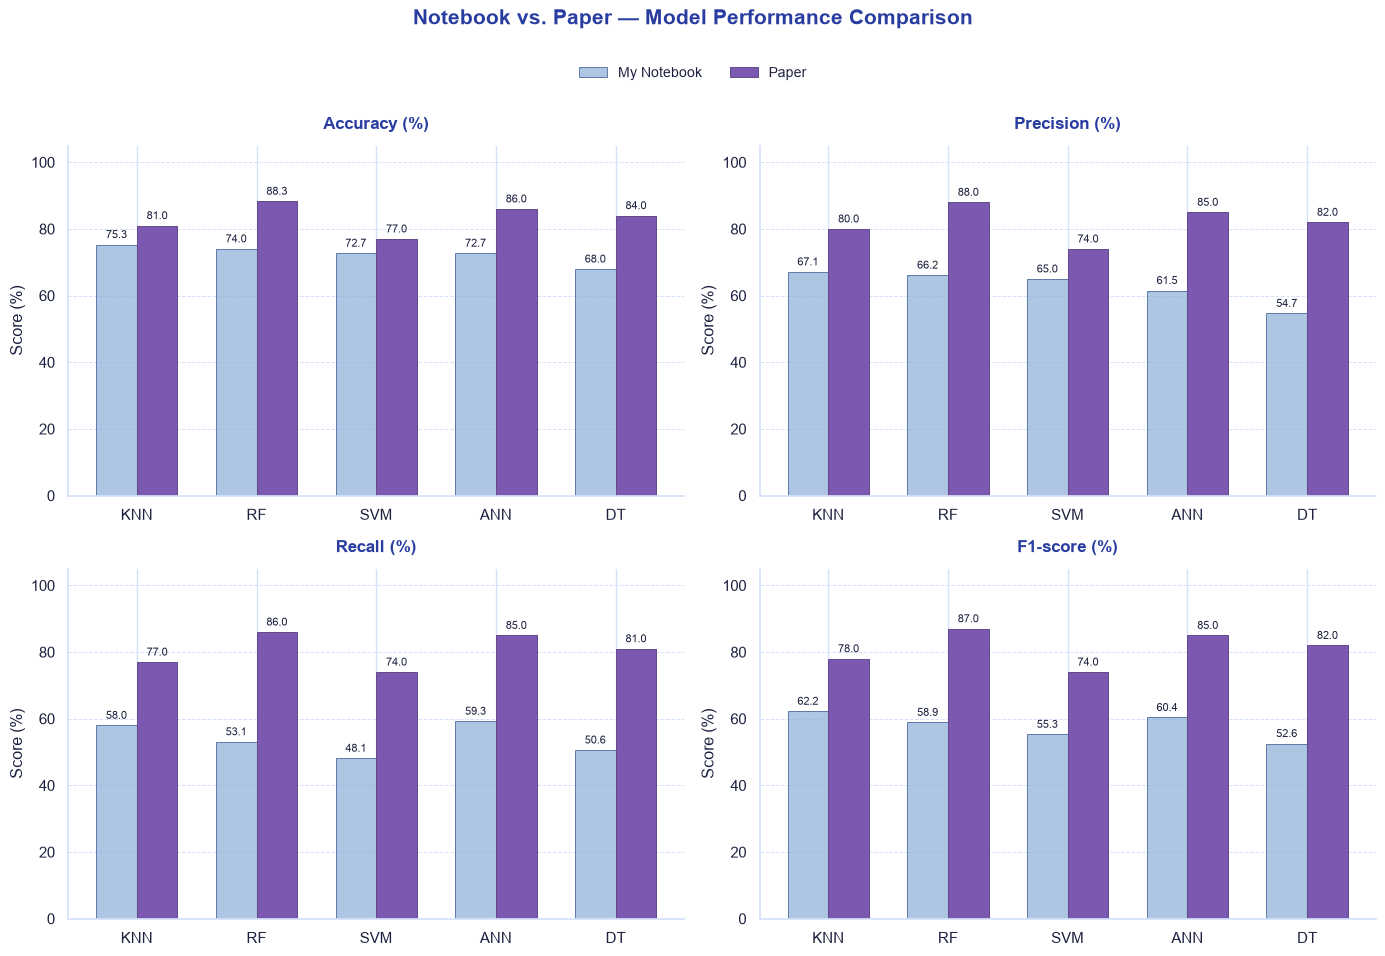

,Model,Metric,Notebook (%),Paper (%),Difference (Notebook - Paper)
0,KNN,Accuracy (%),75.32,81.00,-5.68
1,KNN,Precision (%),67.14,80.00,-12.86
2,KNN,Recall (%),58.02,77.00,-18.98
3,KNN,F1-score (%),62.25,78.00,-15.75
4,RF,Accuracy (%),74.03,88.31,-14.28
5,RF,Precision (%),66.15,88.00,-21.85
6,RF,Recall (%),53.09,86.00,-32.91
7,RF,F1-score (%),58.90,87.00,-28.10
8,SVM,Accuracy (%),72.73,77.00,-4.27
9,SVM,Precision (%),65.00,74.00,-9.00


In [31]:

paper_results = pd.DataFrame({
    "Model": ["KNN", "RF", "SVM", "ANN", "DT"],
    "Accuracy (%)": [81.00, 88.31, 77.00, 86.00, 84.00],
    "Precision (%)": [80.00, 88.00, 74.00, 85.00, 82.00],
    "Recall (%)": [77.00, 86.00, 74.00, 85.00, 81.00],
    "F1-score (%)": [78.00, 87.00, 74.00, 85.00, 82.00]
})


notebook_key = next(
    (key for key in all_results if key.startswith("Table 3")),
    None
)

if notebook_key is None:
    raise KeyError(
        "نتایج Table 3 پیدا نشد. ابتدا سلول اجرای آزمایش‌ها را اجرا کن."
    )

notebook_results = all_results[notebook_key].copy()


comparison = notebook_results.merge(
    paper_results,
    on="Model",
    suffixes=("_notebook", "_paper")
)


PURPLE = PRIMARY
DARK_PURPLE = SECONDARY
LIGHT_PURPLE = LIGHT_2
BLUE = ACCENT
LIGHT_BLUE = LIGHT_3
TEXT = TEXT_COLOR
GRID = GRID_COLOR

metrics = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-score (%)"
]


fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

x = np.arange(len(comparison["Model"]))
bar_width = 0.34

for i, metric in enumerate(metrics):
    ax = axes[i]

    notebook_values = comparison[f"{metric}_notebook"]
    paper_values = comparison[f"{metric}_paper"]

    bars1 = ax.bar(
        x - bar_width / 2,
        notebook_values,
        width=bar_width,
        label="My Notebook",
        color=BLUE,
        edgecolor="#284E84",
        linewidth=0.7,
        alpha=0.7
    )

    bars2 = ax.bar(
        x + bar_width / 2,
        paper_values,
        width=bar_width,
        label="Paper",
        color=LIGHT_PURPLE,
        edgecolor=PURPLE,
        linewidth=0.7
    )

    # نمایش مقدار هر میله
    ax.bar_label(
        bars1, fmt="%.1f", padding=3,
        fontsize=8, color=TEXT
    )
    ax.bar_label(
        bars2, fmt="%.1f", padding=3,
        fontsize=8, color=TEXT
    )

    ax.set_title(
        metric,
        color=DARK_PURPLE,
        fontsize=12,
        fontweight="bold",
        pad=12
    )
    ax.set_xticks(x)
    ax.set_xticklabels(comparison["Model"], color=TEXT)
    ax.set_ylim(0, 105)
    ax.set_ylabel("Score (%)", color=TEXT)

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.7,
        color=GRID
    )
    ax.set_axisbelow(True)
    ax.set_facecolor("white")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(GRID)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=TEXT)

fig.patch.set_facecolor("white")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 1.01),
    fontsize=10
)

fig.suptitle(
    "Notebook vs. Paper — Model Performance Comparison",
    fontsize=15,
    fontweight="bold",
    color=DARK_PURPLE,
    y=1.06
)

plt.tight_layout()
plt.show()


difference_rows = []

for _, row in comparison.iterrows():
    for metric in metrics:
        difference_rows.append({
            "Model": row["Model"],
            "Metric": metric,
            "Notebook (%)": row[f"{metric}_notebook"],
            "Paper (%)": row[f"{metric}_paper"],
            "Difference (Notebook - Paper)": round(
                row[f"{metric}_notebook"] - row[f"{metric}_paper"],
                2
            )
        })

difference_df = pd.DataFrame(difference_rows)

display(
    difference_df.style
    .format({
        "Notebook (%)": "{:.2f}",
        "Paper (%)": "{:.2f}",
        "Difference (Notebook - Paper)": "{:+.2f}"
    })
    .set_caption("Numerical Difference: Notebook vs. Paper")
    .set_properties(**{
        "text-align": "center",
        "color": TEXT,
        "padding": "7px",
        "border": "1px solid #D9DDF5"
    })
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", PURPLE),
                ("padding", "9px")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("background-color", PURPLE),
                ("color", "white"),
                ("text-align", "center"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "tbody tr:nth-child(even)",
            "props": [("background-color", "#DCE5FB")]
        },
        {
            "selector": "tbody tr:nth-child(odd)",
            "props": [("background-color", "white")]
        }
    ])
)


## Conclusion

The notebook reports actual test-set metrics and keeps them separate from the published reference values. Small or large differences can occur because the paper does not fully specify the split, preprocessing, random seeds, and model parameters. Do not replace measured results with the paper's numbers.
